# Deep Neural Network for Diabetes 30-Day Readmission Prediction

## 1. Introduction

This notebook develops a Deep Neural Network (DNN) for predicting 30-day hospital readmission among patients with diabetes.

The model uses the prepared Experiment B dataset from the preceding centralised machine-learning experiments.

The existing patient-grouped training, validation and test partitions will be reused to ensure a fair comparison with Logistic Regression, Random Forest and XGBoost.

## 2. Objectives

1. Develop a neural-network-based readmission prediction model.
2. Address class imbalance during training.
3. Optimise the architecture using validation data.
4. Evaluate predictive performance using appropriate classification metrics.
5. Investigate explainability using SHAP.
6. Compare DNN performance with the existing centralised machine-learning models.
7. Establish a reusable DNN architecture for subsequent federated-learning experiments.

## 3. Dataset

- Dataset: UCI Diabetes 130-US Hospitals
- Feature representation: Experiment B
- Original features: 52
- Expected encoded features: 915
- Target: `readmission_30d`
- Positive class: Readmission within 30 days (`1`)
- Negative class: No readmission within 30 days (`0`)

## 4. Experimental methodology

The existing patient-grouped train, validation and test partitions will be retained. Preprocessing will not be refitted, and the test set will remain untouched during model development.

## 1. Import Libraries and Load Prepared Data

This section imports the required libraries and loads the preprocessed Experiment B datasets exported from the previous notebook.

The sparse feature matrices, target labels, patient-group identifiers and fitted preprocessing pipeline are loaded without modifying the original data.

The purpose is to maintain consistency between the existing machine-learning experiments and the upcoming Deep Neural Network experiment.

In [1]:
import os
import json
import random
import joblib
import numpy as np
import pandas as pd
import scipy.sparse as sp

from pathlib import Path

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.1
Pandas: 3.0.3


In [2]:
current_path = Path.cwd()

DNN_DATA_DIR = None

for path in [current_path, *current_path.parents]:
    candidate = path / "models" / "artifacts" / "dnn_data"

    if candidate.exists():
        DNN_DATA_DIR = candidate
        break

if DNN_DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate models/artifacts/dnn_data. "
        "Check the notebook location or project directory."
    )

print("Data directory:", DNN_DATA_DIR)
print("Files:", sorted(p.name for p in DNN_DATA_DIR.iterdir()))

Data directory: /Users/ananyosen/Documents/ADLCS Proj/models/artifacts/dnn_data
Files: ['X_test.npz', 'X_train.npz', 'X_validation.npz', 'metadata.json', 'preprocessor.joblib', 'test_metadata.csv', 'train_metadata.csv', 'validation_metadata.csv']


In [3]:
X_train_dnn = sp.load_npz(
    DNN_DATA_DIR / "X_train.npz"
)

X_validation_dnn = sp.load_npz(
    DNN_DATA_DIR / "X_validation.npz"
)

X_test_dnn = sp.load_npz(
    DNN_DATA_DIR / "X_test.npz"
)

print("Training:", X_train_dnn.shape)
print("Validation:", X_validation_dnn.shape)
print("Testing:", X_test_dnn.shape)

Training: (70055, 915)
Validation: (15059, 915)
Testing: (15000, 915)


In [4]:
train_metadata = pd.read_csv(
    DNN_DATA_DIR / "train_metadata.csv",
    index_col="row_index"
)

validation_metadata = pd.read_csv(
    DNN_DATA_DIR / "validation_metadata.csv",
    index_col="row_index"
)

test_metadata = pd.read_csv(
    DNN_DATA_DIR / "test_metadata.csv",
    index_col="row_index"
)

y_train_dnn = train_metadata["target"].astype(int)
y_validation_dnn = validation_metadata["target"].astype(int)
y_test_dnn = test_metadata["target"].astype(int)

groups_train_dnn = train_metadata["patient_group"]
groups_validation_dnn = validation_metadata["patient_group"]
groups_test_dnn = test_metadata["patient_group"]

print("Training labels:", y_train_dnn.shape)
print("Validation labels:", y_validation_dnn.shape)
print("Testing labels:", y_test_dnn.shape)

print("Patient groups loaded successfully.")

Training labels: (70055,)
Validation labels: (15059,)
Testing labels: (15000,)
Patient groups loaded successfully.


In [5]:
with open(DNN_DATA_DIR / "metadata.json", "r") as f:
    dnn_metadata = json.load(f)

preprocessor_dnn = joblib.load(
    DNN_DATA_DIR / "preprocessor.joblib"
)

feature_names_dnn = dnn_metadata["feature_names"]

print("Experiment:", dnn_metadata["experiment"])
print("Target:", dnn_metadata["target"])
print("Encoded features:", len(feature_names_dnn))
print("Preprocessor loaded:", type(preprocessor_dnn))

Experiment: Experiment B - Grouped ICD-9 diagnosis features
Target: readmission_30d
Encoded features: 915
Preprocessor loaded: <class 'sklearn.compose._column_transformer.ColumnTransformer'>


In [6]:
assert X_train_dnn.shape == (70055, 915)
assert X_validation_dnn.shape == (15059, 915)
assert X_test_dnn.shape == (15000, 915)

assert len(y_train_dnn) == X_train_dnn.shape[0]
assert len(y_validation_dnn) == X_validation_dnn.shape[0]
assert len(y_test_dnn) == X_test_dnn.shape[0]

assert len(feature_names_dnn) == 915

assert np.isfinite(X_train_dnn.data).all()
assert np.isfinite(X_validation_dnn.data).all()
assert np.isfinite(X_test_dnn.data).all()

assert set(y_train_dnn.unique()).issubset({0, 1})
assert set(y_validation_dnn.unique()).issubset({0, 1})
assert set(y_test_dnn.unique()).issubset({0, 1})

print("All data integrity checks passed.")

All data integrity checks passed.


In [7]:
train_patients = set(groups_train_dnn)
validation_patients = set(groups_validation_dnn)
test_patients = set(groups_test_dnn)

print("Train-validation overlap:",
      len(train_patients & validation_patients))

print("Train-test overlap:",
      len(train_patients & test_patients))

print("Validation-test overlap:",
      len(validation_patients & test_patients))

assert not (train_patients & validation_patients)
assert not (train_patients & test_patients)
assert not (validation_patients & test_patients)

print("\nPatient-group separation verified.")

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

Patient-group separation verified.


In [8]:
target_distribution = pd.DataFrame({
    "Training": y_train_dnn.value_counts(normalize=True),
    "Validation": y_validation_dnn.value_counts(normalize=True),
    "Testing": y_test_dnn.value_counts(normalize=True)
}).fillna(0)

target_distribution.index = [
    "No readmission (0)",
    "Readmission within 30 days (1)"
]

print((target_distribution * 100).round(2))

                                Training  Validation  Testing
No readmission (0)                 88.71       88.24     88.8
Readmission within 30 days (1)     11.29       11.76     11.2


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("MPS available:", torch.backends.mps.is_available())

PyTorch version: 2.13.0
CUDA available: False
MPS available: True


In [10]:
# Set reproducibility seeds
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Selected device:", DEVICE)

Selected device: mps


In [11]:
negative_count = int((y_train_dnn == 0).sum())
positive_count = int((y_train_dnn == 1).sum())

pos_weight_value = negative_count / positive_count

print("Negative encounters:", negative_count)
print("Positive encounters:", positive_count)
print("Positive class weight:", round(pos_weight_value, 4))

Negative encounters: 62149
Positive encounters: 7906
Positive class weight: 7.861


In [12]:
class SparseTabularDataset(Dataset):

    def __init__(self, X, y):
        self.X = X.tocsr().astype(np.float32)
        self.y = np.asarray(y, dtype=np.float32)

        assert self.X.shape[0] == len(self.y)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, index):
        features = self.X[index].toarray().ravel()

        return (
            torch.tensor(features, dtype=torch.float32),
            torch.tensor(self.y[index], dtype=torch.float32)
        )

In [13]:
train_dataset = SparseTabularDataset(
    X_train_dnn, y_train_dnn
)

validation_dataset = SparseTabularDataset(
    X_validation_dnn, y_validation_dnn
)

test_dataset = SparseTabularDataset(
    X_test_dnn, y_test_dnn
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 70055
Validation samples: 15059
Testing samples: 15000


In [14]:
BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))

Training batches: 274
Validation batches: 59
Testing batches: 59


In [15]:
class DiabetesReadmissionDNN(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.30):
        super().__init__()

        self.network = nn.Sequential(
            # First hidden layer
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            # Second hidden layer
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            # Third hidden layer
            nn.Linear(256, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            # Binary output
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


input_dim = X_train_dnn.shape[1]

dnn_model = DiabetesReadmissionDNN(
    input_dim=input_dim,
    dropout_rate=0.30
).to(DEVICE)

print(dnn_model)
print("\nModel device:", next(dnn_model.parameters()).device)

total_parameters = sum(
    parameter.numel()
    for parameter in dnn_model.parameters()
)

print("Total trainable parameters:", total_parameters)

DiabetesReadmissionDNN(
  (network): Sequential(
    (0): Linear(in_features=915, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=256, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

Model device: mps:0
Total trainable parameters: 618497


In [16]:
pos_weight_tensor = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor
)

optimizer = optim.AdamW(
    dnn_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", 0.001)
print("Positive class weight:", pos_weight_tensor.item())

Loss function: BCEWithLogitsLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Learning rate: 0.001
Positive class weight: 7.860991477966309


In [17]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for features, labels in loader:
        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(features)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

    return running_loss / len(loader.dataset)


def evaluate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_labels = []
    all_probabilities = []

    with torch.no_grad():
        for features, labels in loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = model(features)
            loss = criterion(logits, labels)

            probabilities = torch.sigmoid(logits)

            running_loss += loss.item() * labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    all_labels = np.asarray(all_labels).astype(int)
    all_probabilities = np.asarray(all_probabilities)

    metrics = {
        "loss": running_loss / len(loader.dataset),
        "roc_auc": roc_auc_score(all_labels, all_probabilities),
        "pr_auc": average_precision_score(all_labels, all_probabilities)
    }

    return metrics, all_labels, all_probabilities


print("Training and evaluation functions defined successfully.")

Training and evaluation functions defined successfully.


In [18]:
EPOCHS = 50
PATIENCE = 7

best_val_pr_auc = -np.inf
epochs_without_improvement = 0

best_model_state = None

training_history = []

print("Maximum epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Model selection metric: Validation PR-AUC")

Maximum epochs: 50
Early stopping patience: 7
Model selection metric: Validation PR-AUC


In [19]:
for epoch in range(1, EPOCHS + 1):

    train_loss = train_one_epoch(
        dnn_model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    val_metrics, _, _ = evaluate_model(
        dnn_model,
        validation_loader,
        criterion,
        DEVICE
    )

    training_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_roc_auc": val_metrics["roc_auc"],
        "val_pr_auc": val_metrics["pr_auc"]
    })

    improved = val_metrics["pr_auc"] > best_val_pr_auc

    if improved:
        best_val_pr_auc = val_metrics["pr_auc"]
        epochs_without_improvement = 0

        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in dnn_model.state_dict().items()
        }

        best_epoch = epoch

    else:
        epochs_without_improvement += 1

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val ROC-AUC: {val_metrics['roc_auc']:.4f} | "
        f"Val PR-AUC: {val_metrics['pr_auc']:.4f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}.")
        break


# Restore the model with the best validation PR-AUC
dnn_model.load_state_dict(best_model_state)

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation PR-AUC:", round(best_val_pr_auc, 4))

Epoch [01/50] Train Loss: 1.1730 | Val Loss: 1.1635 | Val ROC-AUC: 0.6731 | Val PR-AUC: 0.2384
Epoch [02/50] Train Loss: 1.1233 | Val Loss: 1.1640 | Val ROC-AUC: 0.6734 | Val PR-AUC: 0.2391
Epoch [03/50] Train Loss: 1.0931 | Val Loss: 1.1694 | Val ROC-AUC: 0.6744 | Val PR-AUC: 0.2461
Epoch [04/50] Train Loss: 1.0607 | Val Loss: 1.2281 | Val ROC-AUC: 0.6631 | Val PR-AUC: 0.2368
Epoch [05/50] Train Loss: 1.0253 | Val Loss: 1.2584 | Val ROC-AUC: 0.6534 | Val PR-AUC: 0.2254
Epoch [06/50] Train Loss: 0.9855 | Val Loss: 1.2666 | Val ROC-AUC: 0.6542 | Val PR-AUC: 0.2192
Epoch [07/50] Train Loss: 0.9440 | Val Loss: 1.3359 | Val ROC-AUC: 0.6478 | Val PR-AUC: 0.2100
Epoch [08/50] Train Loss: 0.9008 | Val Loss: 1.4273 | Val ROC-AUC: 0.6400 | Val PR-AUC: 0.2097
Epoch [09/50] Train Loss: 0.8558 | Val Loss: 1.4921 | Val ROC-AUC: 0.6426 | Val PR-AUC: 0.2045
Epoch [10/50] Train Loss: 0.8127 | Val Loss: 1.6548 | Val ROC-AUC: 0.6401 | Val PR-AUC: 0.2005

Early stopping triggered at epoch 10.

Training c

,epoch,train_loss,val_loss,val_roc_auc,val_pr_auc
0,1,1.172956,1.163468,0.673080,0.238402
1,2,1.123269,1.163952,0.673369,0.239062
2,3,1.093133,1.169393,0.674449,0.246086
3,4,1.060736,1.228100,0.663131,0.236798
4,5,1.025327,1.258427,0.653353,0.225405
5,6,0.985509,1.266585,0.654195,0.219216
6,7,0.943984,1.335915,0.647809,0.209957
7,8,0.900788,1.427288,0.640031,0.209748
8,9,0.855813,1.492139,0.642552,0.204532
9,10,0.812690,1.654763,0.640109,0.200475


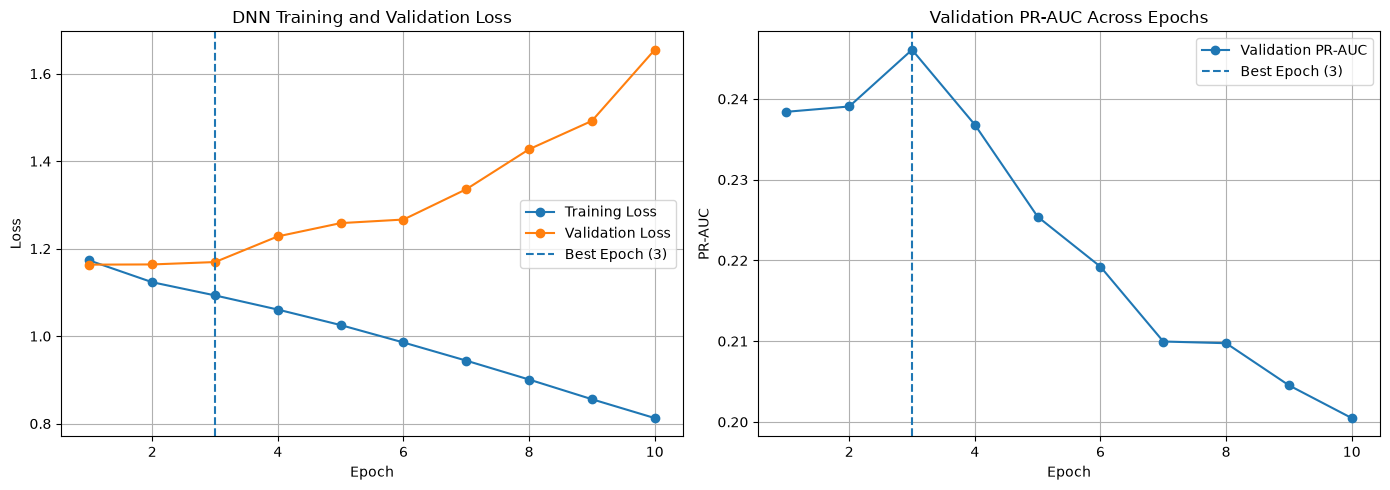

In [20]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(training_history)

display(history_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)
axes[0].set_title("DNN Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# PR-AUC curve
axes[1].plot(
    history_df["epoch"],
    history_df["val_pr_auc"],
    marker="o",
    label="Validation PR-AUC"
)
axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)
axes[1].set_title("Validation PR-AUC Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [21]:
val_metrics, y_val_true, y_val_prob = evaluate_model(
    dnn_model,
    validation_loader,
    criterion,
    DEVICE
)

print("Best DNN validation performance:")
print("ROC-AUC:", round(val_metrics["roc_auc"], 4))
print("PR-AUC:", round(val_metrics["pr_auc"], 4))
print("Validation samples:", len(y_val_true))

Best DNN validation performance:
ROC-AUC: 0.6744
PR-AUC: 0.2461
Validation samples: 15059


In [22]:
from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = precision_recall_curve(
    y_val_true,
    y_val_prob
)

# F1 corresponds to each threshold.
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-12)
)

best_threshold_index = np.argmax(f1_values)
dnn_threshold = float(thresholds[best_threshold_index])

print("Selected DNN threshold:", round(dnn_threshold, 4))
print("Validation precision:", round(precision_values[best_threshold_index], 4))
print("Validation recall:", round(recall_values[best_threshold_index], 4))
print("Validation F1:", round(f1_values[best_threshold_index], 4))

Selected DNN threshold: 0.5522
Validation precision: 0.2114
Validation recall: 0.4602
Validation F1: 0.2897


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss
)

# Generate test probabilities
test_metrics, y_test_true, y_test_prob = evaluate_model(
    dnn_model,
    test_loader,
    criterion,
    DEVICE
)

# Apply the threshold selected using validation data
y_test_pred = (y_test_prob >= dnn_threshold).astype(int)

# Calculate classification metrics
dnn_test_results = {
    "Model": "DNN",
    "Threshold": dnn_threshold,
    "Accuracy": accuracy_score(y_test_true, y_test_pred),
    "Precision": precision_score(y_test_true, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test_true, y_test_pred, zero_division=0),
    "F1": f1_score(y_test_true, y_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_true, y_test_prob),
    "PR-AUC": average_precision_score(y_test_true, y_test_prob),
    "Brier Score": brier_score_loss(y_test_true, y_test_prob)
}

dnn_test_results_df = pd.DataFrame([dnn_test_results])

display(
    dnn_test_results_df.round(4)
)

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test_true, y_test_pred)
print(cm)

print("\nConfusion Matrix Interpretation:")
print("True Negatives:", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives:", cm[1, 1])

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier Score
0,DNN,0.5522,0.732,0.191,0.4304,0.2645,0.6555,0.2082,0.2162



Confusion Matrix:
[[10257  3063]
 [  957   723]]

Confusion Matrix Interpretation:
True Negatives: 10257
False Positives: 3063
False Negatives: 957
True Positives: 723


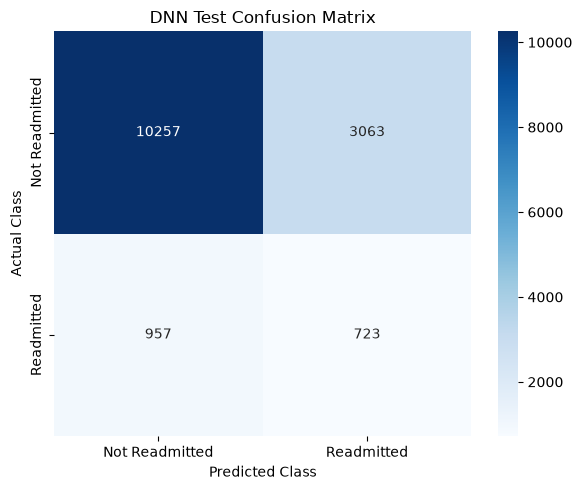

In [24]:
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Readmitted", "Readmitted"],
    yticklabels=["Not Readmitted", "Readmitted"]
)

plt.title("DNN Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

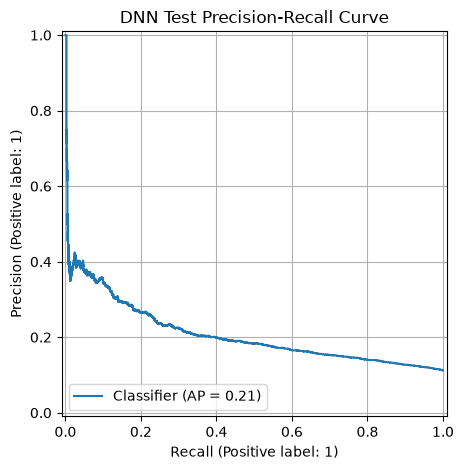

In [25]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test_true,
    y_test_prob
)

plt.title("DNN Test Precision-Recall Curve")
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. DNN Test Evaluation and Comparison

The trained DNN was evaluated on the held-out test set using
the best checkpoint selected by validation PR-AUC.

The best checkpoint was obtained at epoch 3, with a validation
PR-AUC of 0.2461.

The classification threshold of 0.5522 was selected using
validation data by maximising the F1-score.

The DNN achieved a test PR-AUC of 0.2082 and ROC-AUC of
0.6555. Its test F1-score was 0.2645, with recall of 0.4304.

### Observations

- The DNN showed overfitting after the third epoch.
- Early stopping retained the best validation checkpoint.
- The DNN achieved competitive results but did not outperform
  the best centralised tree-based models.
- XGBoost achieved the highest test PR-AUC, while Random Forest
  achieved the highest test F1-score.
- The trained DNN will serve as the neural-network baseline
  for subsequent federated-learning experiments.

The test set was not used for model selection or threshold tuning.